In [ ]:
!pip install -q scikit-learn seaborn

In [ ]:
import os
import shutil
import random
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, DenseNet121
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization,
    GlobalAveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU Available: []


In [ ]:
DATASET_PATH = "/content/CCSN_dataset"

if os.path.exists(DATASET_PATH):
    shutil.rmtree(DATASET_PATH)

!git clone --depth 1 https://github.com/Callmewuxin/CCSN_dataset.git /content/CCSN_dataset

print("Dataset downloaded.")
print("Folders inside dataset:")
print(os.listdir(DATASET_PATH))

Cloning into '/content/CCSN_dataset'...
remote: Enumerating objects: 2539, done.
remote: Counting objects: 100% (2539/2539), done.
remote: Compressing objects: 100% (2539/2539), done.
remote: Total 2539 (delta 0), reused 2539 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (2539/2539), 92.29 MiB | 27.86 MiB/s, done.
Updating files: 100% (2543/2543), done.
Dataset downloaded.
Folders inside dataset:
['Ct', '.git', 'Ci', 'St', 'Sc', 'As', 'Ns', 'Cb', 'Ac', 'Cu', 'Cc', 'Cs']


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 16
SEED = 42

# Increased training time
EPOCHS_HEAD = 25
EPOCHS_FINE = 20

LR_HEAD = 1e-4
LR_FINE = 1e-5

# Updated 5 classes, chosen because they are more visually different
SELECTED_CLASSES = ["Ci", "Cu", "Cb", "Ct", "Ns"]

CLASS_FULL_NAMES = {
    "Ci": "Cirrus",
    "Cu": "Cumulus",
    "Cb": "Cumulonimbus",
    "Ct": "Contrail",
    "Ns": "Nimbostratus"
}

USED_CLASSES = SELECTED_CLASSES
NUM_CLASSES = len(USED_CLASSES)

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("Project Title: Cloud Type Classification Using CNN Architectures")
print("Number of Classes:", NUM_CLASSES)
print("Used Classes:")

for code in USED_CLASSES:
    print(f"{code}: {CLASS_FULL_NAMES[code]}")

Project Title: Cloud Type Classification Using CNN Architectures
Number of Classes: 5
Used Classes:
Ci: Cirrus
Cu: Cumulus
Cb: Cumulonimbus
Ct: Contrail
Ns: Nimbostratus


In [ ]:
image_paths = []
labels = []

for cls in USED_CLASSES:
    class_folder = os.path.join(DATASET_PATH, cls)

    if not os.path.exists(class_folder):
        print("Missing folder:", class_folder)
        continue

    for file in os.listdir(class_folder):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_folder, file))
            labels.append(cls)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("Total selected images:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

Total selected images: 1037

Class distribution:
label
Ns    274
Cb    242
Ct    200
Cu    182
Ci    139
Name: count, dtype: int64


,Cloud Code,Cloud Type,Image Count,Percentage
0,Ci,Cirrus,139,13.40
1,Cu,Cumulus,182,17.55
2,Cb,Cumulonimbus,242,23.34
3,Ct,Contrail,200,19.29
4,Ns,Nimbostratus,274,26.42


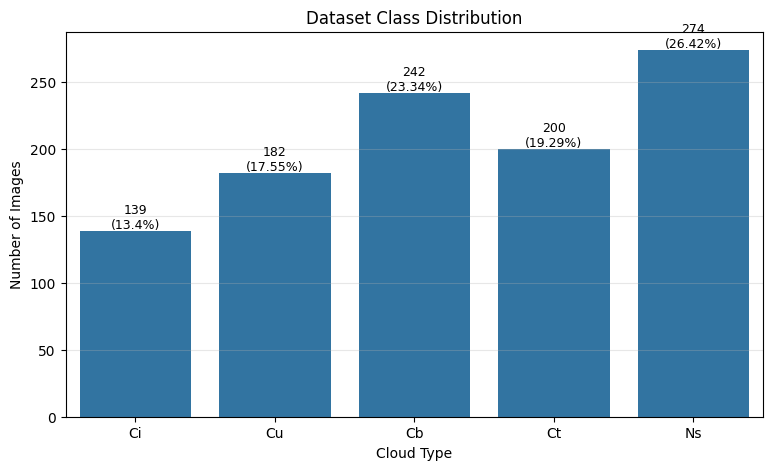

Brief description:
This chart shows the number of images per selected cloud class. A more balanced dataset usually helps the models learn each class more fairly.


In [ ]:
class_counts = df["label"].value_counts().reindex(USED_CLASSES)
class_percent = (class_counts / class_counts.sum() * 100).round(2)

dataset_summary = pd.DataFrame({
    "Cloud Code": USED_CLASSES,
    "Cloud Type": [CLASS_FULL_NAMES[c] for c in USED_CLASSES],
    "Image Count": class_counts.values,
    "Percentage": class_percent.values
})

display(dataset_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=dataset_summary,
    x="Cloud Code",
    y="Image Count"
)
plt.title("Dataset Class Distribution")
plt.xlabel("Cloud Type")
plt.ylabel("Number of Images")

for i, row in dataset_summary.iterrows():
    plt.text(
        i,
        row["Image Count"] + 2,
        f'{row["Image Count"]}\n({row["Percentage"]}%)',
        ha="center",
        fontsize=9
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

print("Brief description:")
print("This chart shows the number of images per selected cloud class. A more balanced dataset usually helps the models learn each class more fairly.")

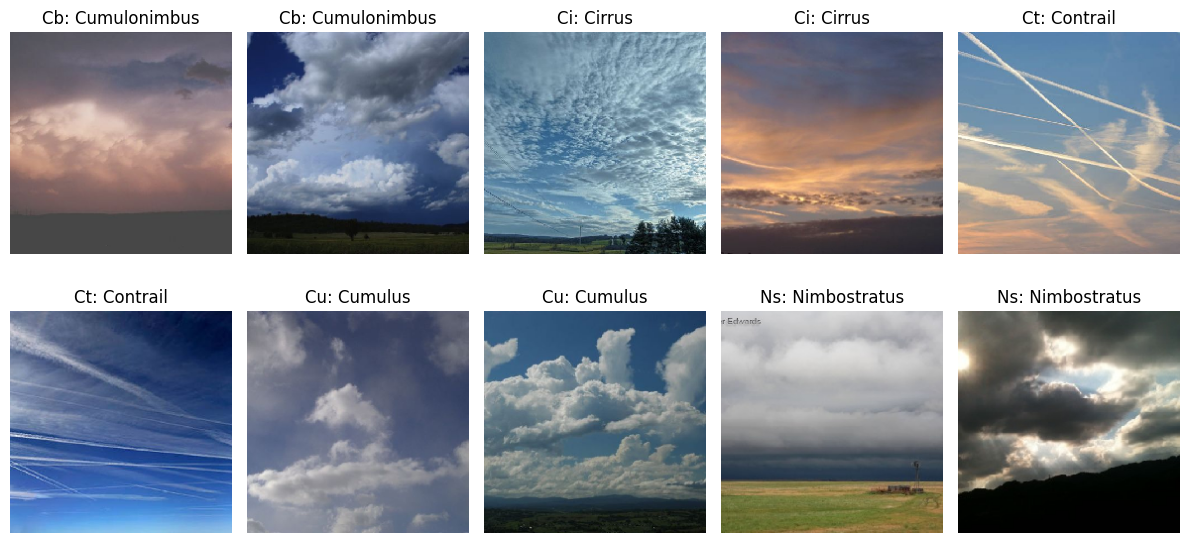

Brief description:
These sample images show the visual differences among the selected cloud classes, such as thin clouds, puffy clouds, storm-like clouds, and layered clouds.


In [ ]:
plt.figure(figsize=(12, 6))

sample_df = df.groupby("label").sample(2, random_state=SEED)

for i, row in enumerate(sample_df.itertuples(), 1):
    img = tf.keras.utils.load_img(row.filepath, target_size=(IMG_SIZE, IMG_SIZE))
    plt.subplot(2, 5, i)
    plt.imshow(img)
    plt.title(f"{row.label}: {CLASS_FULL_NAMES[row.label]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Brief description:")
print("These sample images show the visual differences among the selected cloud classes, such as thin clouds, puffy clouds, storm-like clouds, and layered clouds.")

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Testing"],
    "Images": [len(train_df), len(val_df), len(test_df)],
    "Percentage": [
        round(len(train_df) / len(df) * 100, 2),
        round(len(val_df) / len(df) * 100, 2),
        round(len(test_df) / len(df) * 100, 2)
    ]
})

display(split_summary)

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())

Training images: 829
Validation images: 104
Testing images: 104


,Split,Images,Percentage
0,Training,829,79.94
1,Validation,104,10.03
2,Testing,104,10.03



Training class distribution:
label
Ns    219
Cb    193
Ct    160
Cu    146
Ci    111
Name: count, dtype: int64

Validation class distribution:
label
Ns    28
Cb    24
Ct    20
Cu    18
Ci    14
Name: count, dtype: int64

Testing class distribution:
label
Ns    27
Cb    25
Ct    20
Cu    18
Ci    14
Name: count, dtype: int64


,Split,Cloud Code,Cloud Type,Image Count
0,Training,Ci,Cirrus,111
1,Training,Cu,Cumulus,146
2,Training,Cb,Cumulonimbus,193
3,Training,Ct,Contrail,160
4,Training,Ns,Nimbostratus,219
5,Validation,Ci,Cirrus,14
6,Validation,Cu,Cumulus,18
7,Validation,Cb,Cumulonimbus,24
8,Validation,Ct,Contrail,20
9,Validation,Ns,Nimbostratus,28


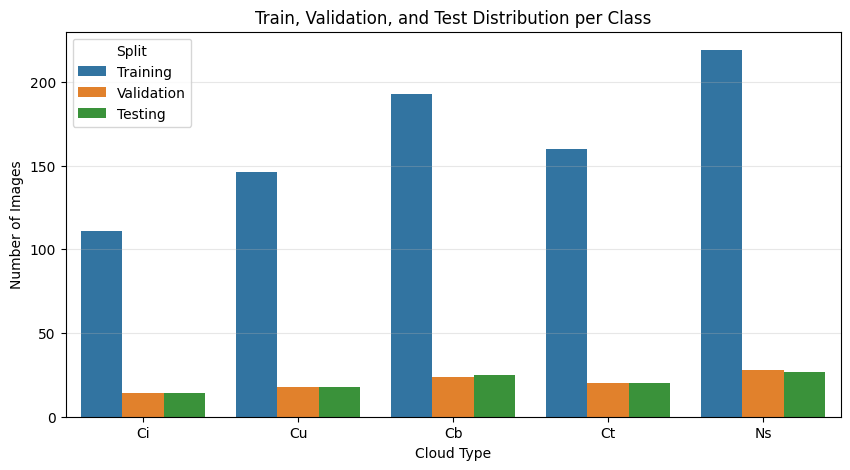

Brief description:
This chart confirms that each split still contains all five cloud classes. This helps make training and testing fair.


In [ ]:
split_counts = []

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    counts = split_df["label"].value_counts().reindex(USED_CLASSES)
    for cls in USED_CLASSES:
        split_counts.append({
            "Split": split_name,
            "Cloud Code": cls,
            "Cloud Type": CLASS_FULL_NAMES[cls],
            "Image Count": counts[cls]
        })

split_counts_df = pd.DataFrame(split_counts)
display(split_counts_df)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=split_counts_df,
    x="Cloud Code",
    y="Image Count",
    hue="Split"
)
plt.title("Train, Validation, and Test Distribution per Class")
plt.xlabel("Cloud Type")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Brief description:")
print("This chart confirms that each split still contains all five cloud classes. This helps make training and testing fair.")

,Cloud Code,Cloud Type,Class Weight
0,Ci,Cirrus,1.493694
1,Cu,Cumulus,1.135616
2,Cb,Cumulonimbus,0.859067
3,Ct,Contrail,1.036250
4,Ns,Nimbostratus,0.757078


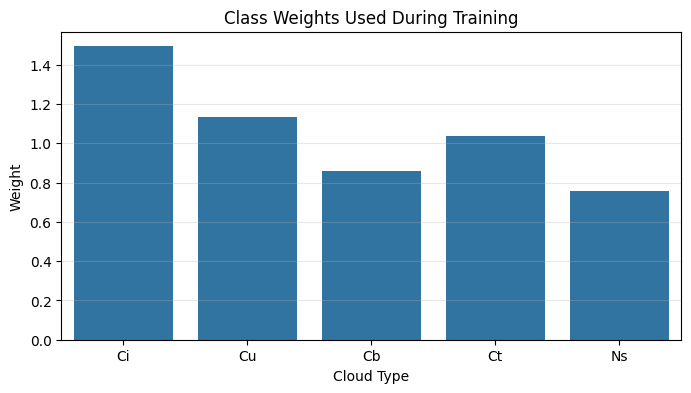

Brief description:
Class weights give more importance to classes with fewer images. This helps improve recall and F1-score for minority classes.


In [ ]:
label_to_index = {label: index for index, label in enumerate(USED_CLASSES)}
index_to_label = {index: label for label, index in label_to_index.items()}

train_labels_int = train_df["label"].map(label_to_index).values

class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_labels_int
)

class_weights = dict(enumerate(class_weights_values))

class_weight_df = pd.DataFrame({
    "Cloud Code": USED_CLASSES,
    "Cloud Type": [CLASS_FULL_NAMES[c] for c in USED_CLASSES],
    "Class Weight": [class_weights[i] for i in range(NUM_CLASSES)]
})

display(class_weight_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=class_weight_df, x="Cloud Code", y="Class Weight")
plt.title("Class Weights Used During Training")
plt.xlabel("Cloud Type")
plt.ylabel("Weight")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Brief description:")
print("Class weights give more importance to classes with fewer images. This helps improve recall and F1-score for minority classes.")

In [ ]:
def create_generators(preprocess_function):
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function,
        rotation_range=20,
        zoom_range=0.20,
        width_shift_range=0.15,
        height_shift_range=0.15,
        shear_range=0.10,
        brightness_range=[0.80, 1.20],
        horizontal_flip=True,
        fill_mode="nearest"
    )

    valid_test_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function
    )

    train_gen = train_datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col="filepath",
        y_col="label",
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=USED_CLASSES,
        shuffle=True,
        seed=SEED
    )

    val_gen = valid_test_datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col="filepath",
        y_col="label",
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=USED_CLASSES,
        shuffle=False
    )

    test_gen = valid_test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col="filepath",
        y_col="label",
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=USED_CLASSES,
        shuffle=False
    )

    return train_gen, val_gen, test_gen

In [ ]:
def build_model(model_name, base_model_class):
    base_model = base_model_class(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base_model.trainable = False

    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)

    x = BatchNormalization()(x)
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.40)(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(0.30)(x)

    outputs = Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)

    model = Model(inputs, outputs, name=model_name)

    model.compile(
        optimizer=Adam(learning_rate=LR_HEAD),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model

In [ ]:
def train_model(model_name, base_model_class, preprocess_function, fine_tune_layers=40):
    print("\n" + "=" * 70)
    print("Training Model:", model_name)
    print("=" * 70)

    train_gen, val_gen, test_gen = create_generators(preprocess_function)

    model, base_model = build_model(model_name, base_model_class)

    checkpoint_path = f"/content/best_{model_name}.keras"

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
        ModelCheckpoint(
            checkpoint_path,
            monitor="val_accuracy",
            save_best_only=True,
            verbose=1
        )
    ]

    start_time = time.time()

    print("\nStage 1: Training classifier head...")

    history_head = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS_HEAD,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )

    print("\nStage 2: Fine-tuning last CNN layers...")

    base_model.trainable = True

    for layer in base_model.layers[:-fine_tune_layers]:
        layer.trainable = False

    for layer in base_model.layers:
        if isinstance(layer, BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=Adam(learning_rate=LR_FINE),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    history_fine = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS_FINE,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )

    training_time = time.time() - start_time

    print("\nEvaluating on test set...")

    test_gen.reset()
    y_prob = model.predict(test_gen, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)
    y_true = test_gen.classes

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    report = classification_report(
        y_true,
        y_pred,
        target_names=USED_CLASSES,
        output_dict=True,
        zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred)

    results = {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Head Epochs": len(history_head.history["loss"]),
        "Fine Tune Epochs": len(history_fine.history["loss"]),
        "Total Epochs": len(history_head.history["loss"]) + len(history_fine.history["loss"]),
        "Training Time Minutes": training_time / 60
    }

    histories = {
        "head": history_head.history,
        "fine": history_fine.history
    }

    predictions = {
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    return model, results, report, cm, histories, predictions

In [ ]:
MODELS = {
    "MobileNetV2": {
        "class": MobileNetV2,
        "preprocess": mobilenet_preprocess,
        "fine_tune_layers": 50
    },
    "EfficientNetB0": {
        "class": EfficientNetB0,
        "preprocess": efficientnet_preprocess,
        "fine_tune_layers": 60
    },
    "DenseNet121": {
        "class": DenseNet121,
        "preprocess": densenet_preprocess,
        "fine_tune_layers": 80
    }
}

all_results = []
all_reports = {}
all_confusion_matrices = {}
all_histories = {}
all_predictions = {}
trained_models = {}

for model_name, config in MODELS.items():
    tf.keras.backend.clear_session()

    model, results, report, cm, histories, predictions = train_model(
        model_name=model_name,
        base_model_class=config["class"],
        preprocess_function=config["preprocess"],
        fine_tune_layers=config["fine_tune_layers"]
    )

    trained_models[model_name] = model
    all_results.append(results)
    all_reports[model_name] = report
    all_confusion_matrices[model_name] = cm
    all_histories[model_name] = histories
    all_predictions[model_name] = predictions

results_df = pd.DataFrame(all_results)
display(results_df)


Training Model: MobileNetV2
Found 829 validated image filenames belonging to 5 classes.
Found 104 validated image filenames belonging to 5 classes.
Found 104 validated image filenames belonging to 5 classes.

Stage 1: Training classifier head...
Epoch 1/25
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 818ms/step - accuracy: 0.2668 - loss: 2.1473
Epoch 1: val_accuracy improved from None to 0.47115, saving model to /content/best_MobileNetV2.keras

Epoch 1: finished saving model to /content/best_MobileNetV2.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 56s 953ms/step - accuracy: 0.3040 - loss: 1.9167 - val_accuracy: 0.4712 - val_loss: 1.3234 - learning_rate: 1.0000e-04
Epoch 2/25
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - accuracy: 0.4016 - loss: 1.5727
Epoch 2: val_accuracy improved from 0.47115 to 0.63462, saving model to /content/best_MobileNetV2.keras

Epoch 2: finished saving model to /content/best_MobileNetV2.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 48s 925ms/step - accuracy: 0.3993 - loss: 1.5203 - val_accuracy: 0.63

7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 705ms/step

Training Model: EfficientNetB0
Found 829 validated image filenames belonging to 5 classes.
Found 104 validated image filenames belonging to 5 classes.
Found 104 validated image filenames belonging to 5 classes.

Stage 1: Training classifier head...
Epoch 1/25
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2134 - loss: 2.0866
Epoch 1: val_accuracy improved from None to 0.37500, saving model to /content/best_EfficientNetB0.keras

Epoch 1: finished saving model to /content/best_EfficientNetB0.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.2630 - loss: 1.9519 - val_accuracy: 0.3750 - val_loss: 1.4549 - learning_rate: 1.0000e-04
Epoch 2/25
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3231 - loss: 1.6737
Epoch 2: val_accuracy improved from 0.37500 to 0.46154, saving model to /content/best_EfficientNetB0.keras

Epoch 2: finished saving model to /content/best_EfficientNetB0.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 

In [ ]:
# Recover completed model results after stopping DenseNet121

print("Number of completed models:", len(all_results))

results_df = pd.DataFrame(all_results)
display(results_df)

print("Available reports:", list(all_reports.keys()))
print("Available confusion matrices:", list(all_confusion_matrices.keys()))
print("Available histories:", list(all_histories.keys()))
print("Available predictions:", list(all_predictions.keys()))

Number of completed models: 2


,Model,Accuracy,Precision,Recall,F1-score,Head Epochs,Fine Tune Epochs,Total Epochs,Training Time Minutes
0,MobileNetV2,0.807692,0.808444,0.807692,0.806186,25,20,45,41.109618
1,EfficientNetB0,0.711538,0.714352,0.711538,0.707184,25,20,45,63.220118


Available reports: ['MobileNetV2', 'EfficientNetB0']
Available confusion matrices: ['MobileNetV2', 'EfficientNetB0']
Available histories: ['MobileNetV2', 'EfficientNetB0']
Available predictions: ['MobileNetV2', 'EfficientNetB0']


In [ ]:
model_name = "MobileNetV2"

mobilenet_results = [r for r in all_results if r["Model"] == model_name][0]
mobilenet_report = all_reports[model_name]
mobilenet_cm = all_confusion_matrices[model_name]
mobilenet_histories = all_histories[model_name]
mobilenet_predictions = all_predictions[model_name]

mobilenet_results_df = pd.DataFrame([mobilenet_results])

mobilenet_display = mobilenet_results_df.copy()

for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    mobilenet_display[col] = (mobilenet_display[col] * 100).round(2)

mobilenet_display["Training Time Minutes"] = mobilenet_display["Training Time Minutes"].round(2)

print("MobileNetV2 Final Results:")
display(mobilenet_display)

MobileNetV2 Final Results:


,Model,Accuracy,Precision,Recall,F1-score,Head Epochs,Fine Tune Epochs,Total Epochs,Training Time Minutes
0,MobileNetV2,80.77,80.84,80.77,80.62,25,20,45,41.11


In [ ]:
# ============================================================
# CLEAN RESULTS TABLE FOR COMPLETED MODELS
# ============================================================

results_display = results_df.copy()

for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    results_display[col] = (results_display[col] * 100).round(2)

if "Training Time Minutes" in results_display.columns:
    results_display["Training Time Minutes"] = results_display["Training Time Minutes"].round(2)

results_display = results_display.sort_values(by="F1-score", ascending=False)

print("Completed Model Comparison:")
display(results_display)

print("Brief description:")
print("This table shows the completed CNN model results after stopping the unfinished DenseNet121 training.")
print("The models are ranked based on weighted F1-score because it balances precision and recall.")

Completed Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score,Head Epochs,Fine Tune Epochs,Total Epochs,Training Time Minutes
0,MobileNetV2,80.77,80.84,80.77,80.62,25,20,45,41.11
1,EfficientNetB0,71.15,71.44,71.15,70.72,25,20,45,63.22


Brief description:
This table shows the completed CNN model results after stopping the unfinished DenseNet121 training.
The models are ranked based on weighted F1-score because it balances precision and recall.


In [ ]:
# ============================================================
# EXTRACT MOBILENETV2 RESULTS ONLY
# ============================================================

model_name = "MobileNetV2"

if model_name not in list(all_reports.keys()):
    raise ValueError("MobileNetV2 results are not available. Check if MobileNetV2 finished training.")

mobilenet_results = [r for r in all_results if r["Model"] == model_name][0]
mobilenet_report = all_reports[model_name]
mobilenet_cm = all_confusion_matrices[model_name]
mobilenet_histories = all_histories[model_name]
mobilenet_predictions = all_predictions[model_name]

mobilenet_results_df = pd.DataFrame([mobilenet_results])
mobilenet_display = mobilenet_results_df.copy()

for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    mobilenet_display[col] = (mobilenet_display[col] * 100).round(2)

if "Training Time Minutes" in mobilenet_display.columns:
    mobilenet_display["Training Time Minutes"] = mobilenet_display["Training Time Minutes"].round(2)

print("MobileNetV2 Final Results:")
display(mobilenet_display)

MobileNetV2 Final Results:


,Model,Accuracy,Precision,Recall,F1-score,Head Epochs,Fine Tune Epochs,Total Epochs,Training Time Minutes
0,MobileNetV2,80.77,80.84,80.77,80.62,25,20,45,41.11


In [ ]:
# ============================================================
# MOBILENETV2 FINAL INTERPRETATION
# ============================================================

row = mobilenet_display.iloc[0]

print("MOBILENETV2 FINAL RESULT SUMMARY")
print("=" * 70)
print(f"Accuracy: {row['Accuracy']}%")
print(f"Precision: {row['Precision']}%")
print(f"Recall: {row['Recall']}%")
print(f"F1-score: {row['F1-score']}%")

if "Head Epochs" in row:
    print(f"Head Epochs: {row['Head Epochs']}")

if "Fine Tune Epochs" in row:
    print(f"Fine Tune Epochs: {row['Fine Tune Epochs']}")

if "Total Epochs" in row:
    print(f"Total Epochs: {row['Total Epochs']}")

if "Training Time Minutes" in row:
    print(f"Training Time: {row['Training Time Minutes']} minutes")

print("\nBrief description:")
print("MobileNetV2 was selected for detailed analysis because it is lightweight, efficient, and achieved strong performance in the cloud type classification task.")
print("Accuracy measures the overall correctness of the model.")
print("Precision shows how reliable the model predictions are when it predicts a cloud class.")
print("Recall shows how well the model detects actual images from each cloud class.")
print("F1-score gives the best overall balance between precision and recall.")

MOBILENETV2 FINAL RESULT SUMMARY
Accuracy: 80.77%
Precision: 80.84%
Recall: 80.77%
F1-score: 80.62%
Head Epochs: 25
Fine Tune Epochs: 20
Total Epochs: 45
Training Time: 41.11 minutes

Brief description:
MobileNetV2 was selected for detailed analysis because it is lightweight, efficient, and achieved strong performance in the cloud type classification task.
Accuracy measures the overall correctness of the model.
Precision shows how reliable the model predictions are when it predicts a cloud class.
Recall shows how well the model detects actual images from each cloud class.
F1-score gives the best overall balance between precision and recall.


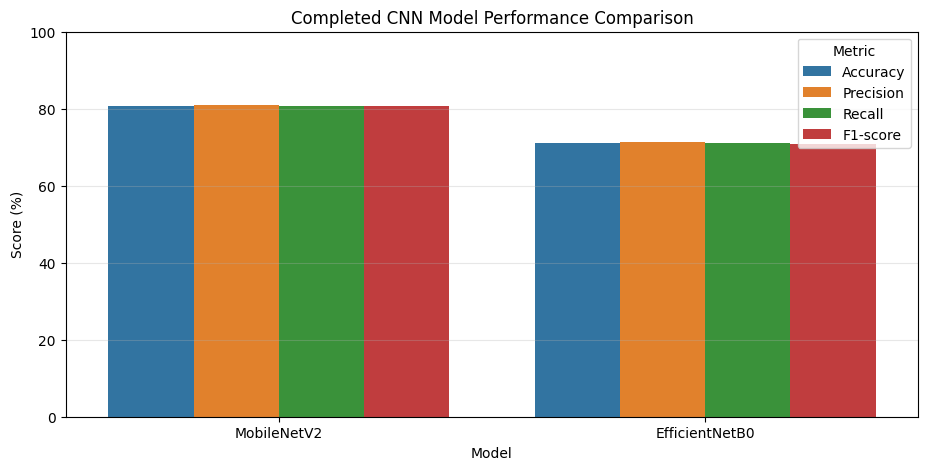

Brief description:
This chart compares the completed CNN models using accuracy, precision, recall, and F1-score.
Higher values indicate better classification performance.


In [ ]:
# ============================================================
# COMPLETED MODEL COMPARISON BAR CHART
# ============================================================

metrics_long = results_display.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=metrics_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Completed CNN Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Metric")
plt.show()

print("Brief description:")
print("This chart compares the completed CNN models using accuracy, precision, recall, and F1-score.")
print("Higher values indicate better classification performance.")

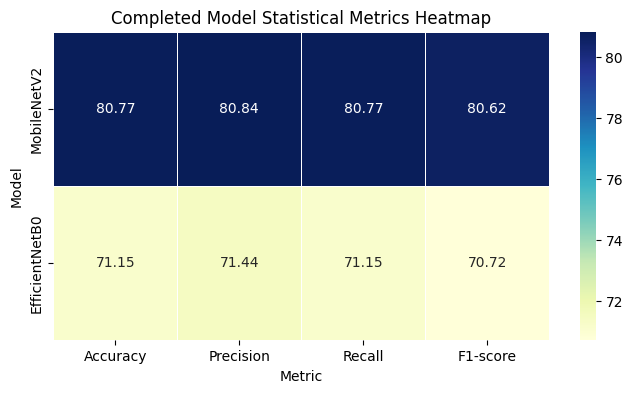

Brief description:
This heatmap summarizes the statistical results of the completed models.
Darker cells represent higher metric scores.


In [ ]:
# ============================================================
# COMPLETED MODEL METRICS HEATMAP
# ============================================================

metrics_heatmap = results_display.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

plt.figure(figsize=(8, 4))
sns.heatmap(
    metrics_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Completed Model Statistical Metrics Heatmap")
plt.xlabel("Metric")
plt.ylabel("Model")
plt.show()

print("Brief description:")
print("This heatmap summarizes the statistical results of the completed models.")
print("Darker cells represent higher metric scores.")

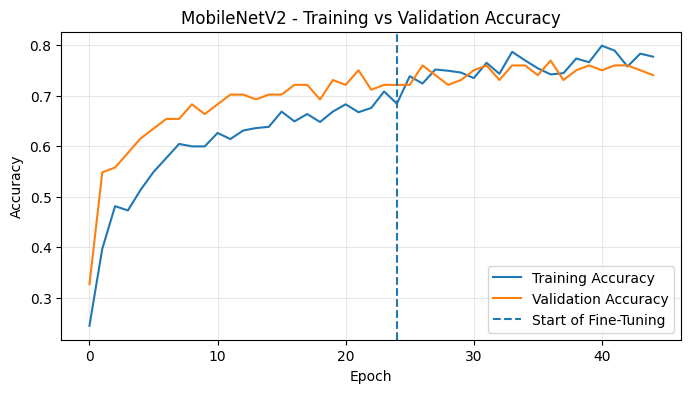

Brief description:
This graph shows how MobileNetV2 learned across epochs.
Training accuracy measures learning on the training set, while validation accuracy measures generalization on unseen validation images.


In [ ]:
# ============================================================
# MOBILENETV2 TRAINING VS VALIDATION ACCURACY
# ============================================================

def merge_history(histories, metric):
    head_values = histories["head"].get(metric, [])
    fine_values = histories["fine"].get(metric, [])
    return head_values + fine_values

train_acc = merge_history(mobilenet_histories, "accuracy")
val_acc = merge_history(mobilenet_histories, "val_accuracy")
train_loss = merge_history(mobilenet_histories, "loss")
val_loss = merge_history(mobilenet_histories, "val_loss")

fine_start = len(mobilenet_histories["head"]["accuracy"]) - 1

plt.figure(figsize=(8, 4))
plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(x=fine_start, linestyle="--", label="Start of Fine-Tuning")

plt.title("MobileNetV2 - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Brief description:")
print("This graph shows how MobileNetV2 learned across epochs.")
print("Training accuracy measures learning on the training set, while validation accuracy measures generalization on unseen validation images.")

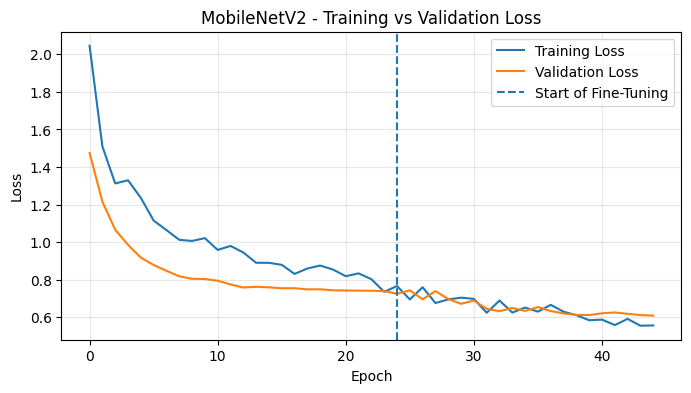

Brief description:
This graph shows the training and validation loss of MobileNetV2.
Lower loss means the model is improving in classifying cloud images.
If validation loss increases while training loss decreases, that may indicate overfitting.


In [ ]:
# ============================================================
# MOBILENETV2 TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 4))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(x=fine_start, linestyle="--", label="Start of Fine-Tuning")

plt.title("MobileNetV2 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Brief description:")
print("This graph shows the training and validation loss of MobileNetV2.")
print("Lower loss means the model is improving in classifying cloud images.")
print("If validation loss increases while training loss decreases, that may indicate overfitting.")

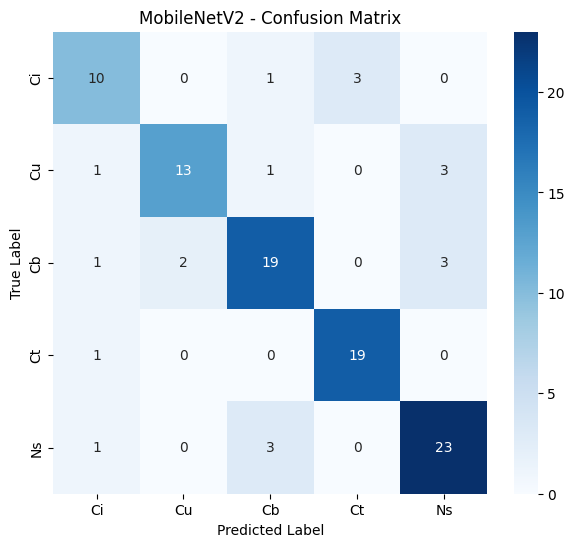

Brief description:
The diagonal values show correct predictions.
The off-diagonal values show which cloud classes were confused with other classes.


In [ ]:
# ============================================================
# MOBILENETV2 CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(7, 6))
sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=USED_CLASSES,
    yticklabels=USED_CLASSES
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print("Brief description:")
print("The diagonal values show correct predictions.")
print("The off-diagonal values show which cloud classes were confused with other classes.")

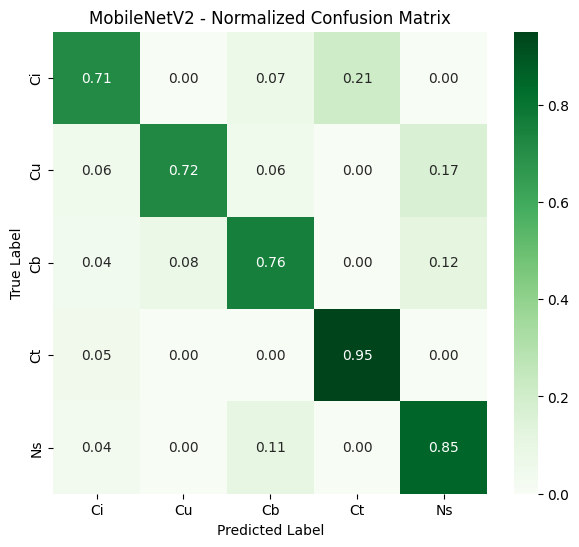

Brief description:
This normalized confusion matrix shows the percentage of correct and incorrect predictions for each cloud class.
Values closer to 1.00 on the diagonal mean stronger class-level performance.


In [ ]:
# ============================================================
# MOBILENETV2 NORMALIZED CONFUSION MATRIX
# ============================================================

mobilenet_cm_norm = mobilenet_cm.astype("float") / mobilenet_cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 6))
sns.heatmap(
    mobilenet_cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    xticklabels=USED_CLASSES,
    yticklabels=USED_CLASSES
)

plt.title("MobileNetV2 - Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print("Brief description:")
print("This normalized confusion matrix shows the percentage of correct and incorrect predictions for each cloud class.")
print("Values closer to 1.00 on the diagonal mean stronger class-level performance.")

In [ ]:
# ============================================================
# MOBILENETV2 PER-CLASS STATISTICAL RESULTS
# ============================================================

mobilenet_per_class_rows = []

for cls in USED_CLASSES:
    mobilenet_per_class_rows.append({
        "Cloud Code": cls,
        "Cloud Type": CLASS_FULL_NAMES[cls],
        "Precision": mobilenet_report[cls]["precision"] * 100,
        "Recall": mobilenet_report[cls]["recall"] * 100,
        "F1-score": mobilenet_report[cls]["f1-score"] * 100,
        "Support": mobilenet_report[cls]["support"]
    })

mobilenet_per_class_df = pd.DataFrame(mobilenet_per_class_rows)

print("MobileNetV2 Per-Class Statistical Results:")
display(mobilenet_per_class_df.round(2))

print("Brief description:")
print("This table shows how MobileNetV2 performed for each individual cloud class.")
print("Support refers to the number of test images for each class.")

MobileNetV2 Per-Class Statistical Results:


,Cloud Code,Cloud Type,Precision,Recall,F1-score,Support
0,Ci,Cirrus,71.43,71.43,71.43,14.0
1,Cu,Cumulus,86.67,72.22,78.79,18.0
2,Cb,Cumulonimbus,79.17,76.00,77.55,25.0
3,Ct,Contrail,86.36,95.00,90.48,20.0
4,Ns,Nimbostratus,79.31,85.19,82.14,27.0


Brief description:
This table shows how MobileNetV2 performed for each individual cloud class.
Support refers to the number of test images for each class.


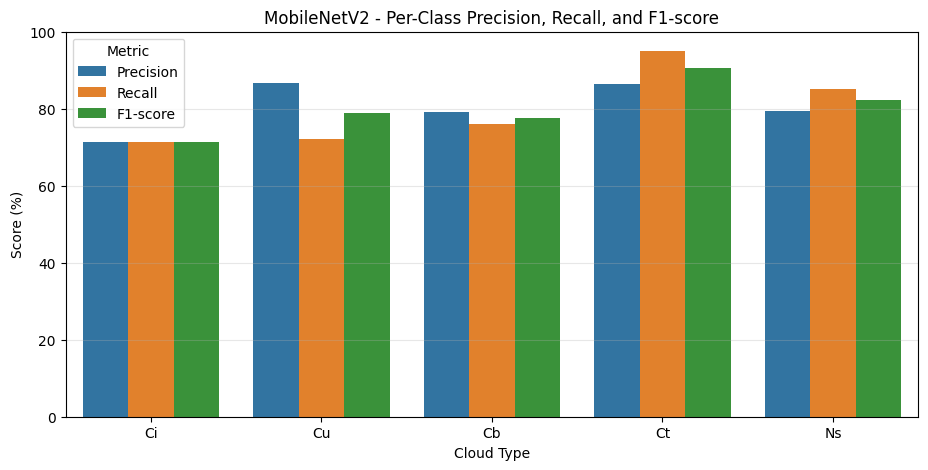

Brief description:
This chart shows the precision, recall, and F1-score of MobileNetV2 for each cloud type.
It helps identify which cloud classes were easier or harder for the model to classify.


In [ ]:
# ============================================================
# MOBILENETV2 PER-CLASS PERFORMANCE VISUALIZATION
# ============================================================

mobilenet_per_class_long = mobilenet_per_class_df.melt(
    id_vars=["Cloud Code", "Cloud Type"],
    value_vars=["Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=mobilenet_per_class_long,
    x="Cloud Code",
    y="Score",
    hue="Metric"
)

plt.title("MobileNetV2 - Per-Class Precision, Recall, and F1-score")
plt.xlabel("Cloud Type")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Metric")
plt.show()

print("Brief description:")
print("This chart shows the precision, recall, and F1-score of MobileNetV2 for each cloud type.")
print("It helps identify which cloud classes were easier or harder for the model to classify.")

In [ ]:
# ============================================================
# MOBILENETV2 FULL CLASSIFICATION REPORT
# ============================================================

mobilenet_report_df = pd.DataFrame(mobilenet_report).transpose()

print("MobileNetV2 Full Classification Report:")
display(mobilenet_report_df.round(4))

print("Brief description:")
print("The classification report provides detailed performance values for each class.")
print("Macro average treats all classes equally, while weighted average considers the number of images per class.")

MobileNetV2 Full Classification Report:


,precision,recall,f1-score,support
Ci,0.7143,0.7143,0.7143,14.0000
Cu,0.8667,0.7222,0.7879,18.0000
Cb,0.7917,0.7600,0.7755,25.0000
Ct,0.8636,0.9500,0.9048,20.0000
Ns,0.7931,0.8519,0.8214,27.0000
accuracy,0.8077,0.8077,0.8077,0.8077
macro avg,0.8059,0.7997,0.8008,104.0000
weighted avg,0.8084,0.8077,0.8062,104.0000


Brief description:
The classification report provides detailed performance values for each class.
Macro average treats all classes equally, while weighted average considers the number of images per class.


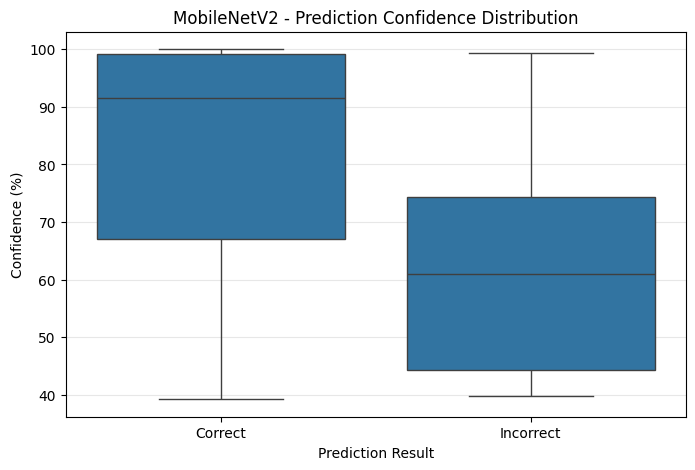

Brief description:
This chart shows how confident MobileNetV2 was in correct and incorrect predictions.
A reliable model usually has higher confidence for correct predictions and lower confidence for incorrect ones.


In [ ]:
# ============================================================
# MOBILENETV2 PREDICTION CONFIDENCE ANALYSIS
# ============================================================

y_true = mobilenet_predictions["y_true"]
y_pred = mobilenet_predictions["y_pred"]
y_prob = mobilenet_predictions["y_prob"]

confidence = np.max(y_prob, axis=1) * 100
correct = y_true == y_pred

confidence_df = pd.DataFrame({
    "Confidence": confidence,
    "Prediction Result": ["Correct" if c else "Incorrect" for c in correct]
})

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=confidence_df,
    x="Prediction Result",
    y="Confidence"
)

plt.title("MobileNetV2 - Prediction Confidence Distribution")
plt.xlabel("Prediction Result")
plt.ylabel("Confidence (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Brief description:")
print("This chart shows how confident MobileNetV2 was in correct and incorrect predictions.")
print("A reliable model usually has higher confidence for correct predictions and lower confidence for incorrect ones.")

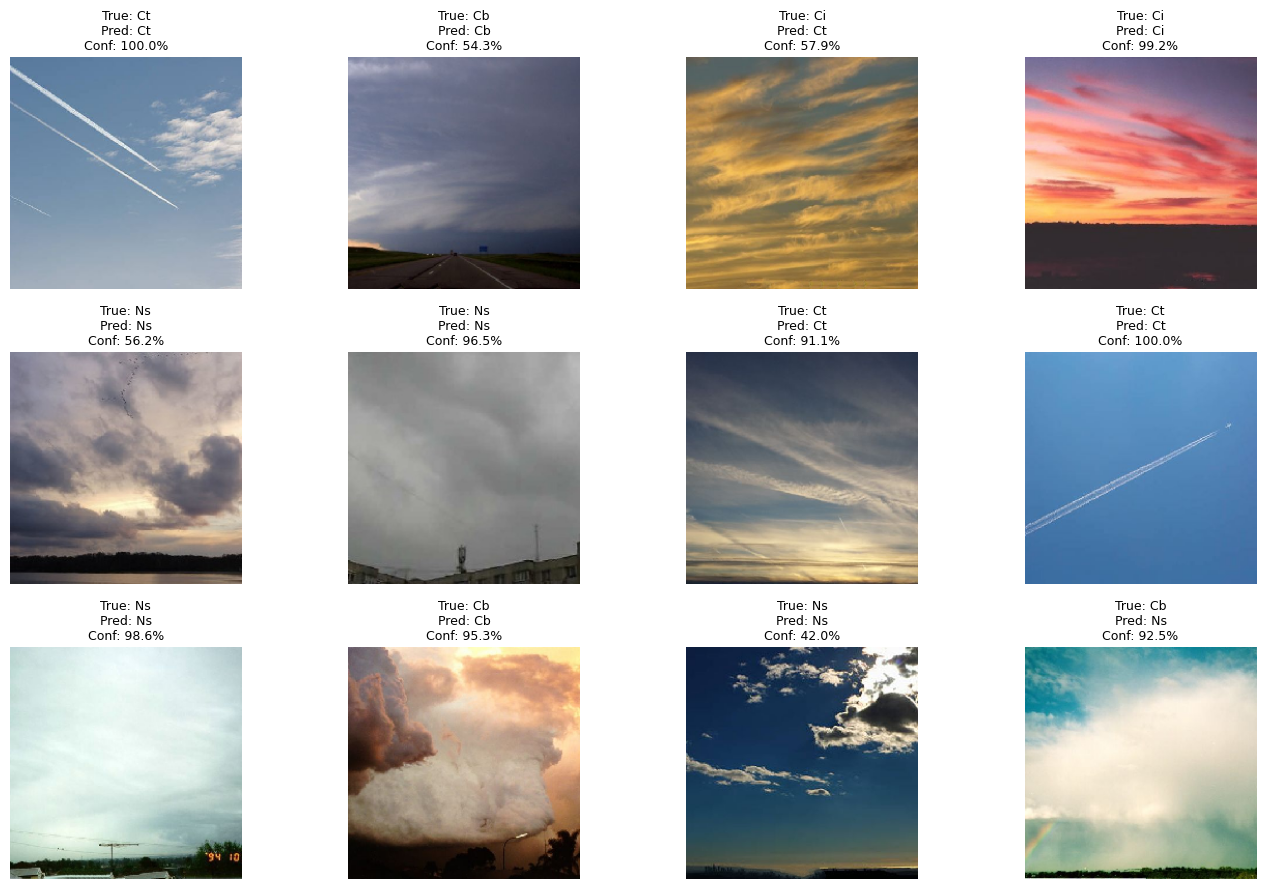

Brief description:
These sample predictions show how MobileNetV2 classified selected test images.
They help visually inspect whether the predicted cloud labels are reasonable.


In [ ]:
# ============================================================
# MOBILENETV2 SAMPLE TEST PREDICTIONS
# ============================================================

test_display_df = test_df.reset_index(drop=True).copy()

test_display_df["True Index"] = y_true
test_display_df["Pred Index"] = y_pred
test_display_df["True Label"] = [USED_CLASSES[i] for i in y_true]
test_display_df["Predicted Label"] = [USED_CLASSES[i] for i in y_pred]
test_display_df["Confidence"] = confidence
test_display_df["Correct"] = test_display_df["True Label"] == test_display_df["Predicted Label"]

sample_predictions = test_display_df.sample(
    min(12, len(test_display_df)),
    random_state=SEED
)

plt.figure(figsize=(14, 9))

for i, (_, row) in enumerate(sample_predictions.iterrows(), 1):
    img = tf.keras.utils.load_img(row["filepath"], target_size=(IMG_SIZE, IMG_SIZE))

    plt.subplot(3, 4, i)
    plt.imshow(img)

    title = (
        f"True: {row['True Label']}\n"
        f"Pred: {row['Predicted Label']}\n"
        f"Conf: {row['Confidence']:.1f}%"
    )

    plt.title(title, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Brief description:")
print("These sample predictions show how MobileNetV2 classified selected test images.")
print("They help visually inspect whether the predicted cloud labels are reasonable.")

Total test images: 104
Correct predictions: 84
Incorrect predictions: 20

Most common MobileNetV2 misclassifications:


,True Label,Predicted Label,Count
2,Cb,Ns,3
8,Cu,Ns,3
4,Ci,Ct,3
9,Ns,Cb,3
1,Cb,Cu,2
0,Cb,Ci,1
3,Ci,Cb,1
6,Cu,Cb,1
5,Ct,Ci,1
7,Cu,Ci,1


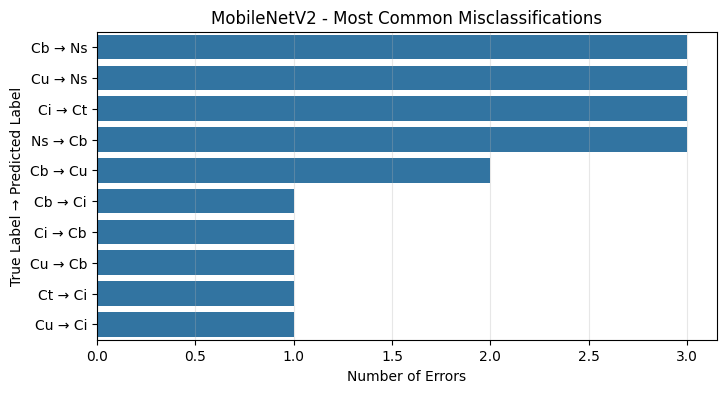

Brief description:
This chart shows which cloud types MobileNetV2 confused most often.


In [ ]:
# ============================================================
# MOBILENETV2 ERROR ANALYSIS
# ============================================================

wrong_predictions = test_display_df[test_display_df["Correct"] == False]
correct_predictions = test_display_df[test_display_df["Correct"] == True]

print("Total test images:", len(test_display_df))
print("Correct predictions:", len(correct_predictions))
print("Incorrect predictions:", len(wrong_predictions))

if len(wrong_predictions) > 0:
    error_summary = wrong_predictions.groupby(
        ["True Label", "Predicted Label"]
    ).size().reset_index(name="Count").sort_values(by="Count", ascending=False)

    print("\nMost common MobileNetV2 misclassifications:")
    display(error_summary)

    plt.figure(figsize=(8, 4))
    sns.barplot(
        data=error_summary.head(10),
        x="Count",
        y=error_summary.head(10).apply(
            lambda x: f"{x['True Label']} → {x['Predicted Label']}",
            axis=1
        )
    )

    plt.title("MobileNetV2 - Most Common Misclassifications")
    plt.xlabel("Number of Errors")
    plt.ylabel("True Label → Predicted Label")
    plt.grid(axis="x", alpha=0.3)
    plt.show()

    print("Brief description:")
    print("This chart shows which cloud types MobileNetV2 confused most often.")
else:
    print("No incorrect predictions found.")

In [ ]:
# ============================================================
# FINAL MOBILENETV2 CONCLUSION
# ============================================================

row = mobilenet_display.iloc[0]

print("FINAL CONCLUSION")
print("=" * 70)

print(
    f"MobileNetV2 achieved {row['Accuracy']}% accuracy, "
    f"{row['Precision']}% precision, {row['Recall']}% recall, "
    f"and {row['F1-score']}% weighted F1-score."
)

print("\nBrief conclusion:")
print("MobileNetV2 showed effective performance in classifying the five selected cloud types.")
print("The training and validation curves describe the model's learning behavior.")
print("The confusion matrix and per-class metrics reveal which cloud classes were classified well and which were more difficult.")
print("Overall, MobileNetV2 is a suitable model for this mini project because it provides a good balance between classification performance and computational efficiency.")

FINAL CONCLUSION
MobileNetV2 achieved 80.77% accuracy, 80.84% precision, 80.77% recall, and 80.62% weighted F1-score.

Brief conclusion:
MobileNetV2 showed effective performance in classifying the five selected cloud types.
The training and validation curves describe the model's learning behavior.
The confusion matrix and per-class metrics reveal which cloud classes were classified well and which were more difficult.
Overall, MobileNetV2 is a suitable model for this mini project because it provides a good balance between classification performance and computational efficiency.


In [ ]:
# ============================================================
# SAVE MOBILENETV2 RESULTS
# ============================================================

mobilenet_display.to_csv("/content/mobilenetv2_final_results.csv", index=False)
mobilenet_per_class_df.to_csv("/content/mobilenetv2_per_class_results.csv", index=False)
mobilenet_report_df.to_csv("/content/mobilenetv2_classification_report.csv", index=True)

print("Saved files:")
print("/content/mobilenetv2_final_results.csv")
print("/content/mobilenetv2_per_class_results.csv")
print("/content/mobilenetv2_classification_report.csv")

Saved files:
/content/mobilenetv2_final_results.csv
/content/mobilenetv2_per_class_results.csv
/content/mobilenetv2_classification_report.csv
